In [4]:
import os, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, load_digits, make_classification
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Tạo thư mục data và chuyển 3 file csv vào
os.makedirs("data", exist_ok=True)
for ten in ["hai_vang_trang.csv", "sinh_vien.csv", "sinh_vien_mo_rong.csv"]:
    if os.path.exists(ten):
        shutil.move(ten, os.path.join("data", ten))

print(os.listdir("data"))   # phải thấy 3 file csv

['sinh_vien.csv', 'sinh_vien_mo_rong.csv', 'hai_vang_trang.csv']


In [5]:
X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                  cluster_std=0.9, random_state=0)
y = 1 - y

svm = SVC(kernel="linear", C=1000)
svm.fit(X, y)

w = svm.coef_[0]
b = svm.intercept_[0]
print(f"w1 = {w[0]:.3f}, w2 = {w[1]:.3f}, b = {b:.3f}")
do_dai_w = np.sqrt(w[0] ** 2 + w[1] ** 2)
print(f"Do rong cua le = 2 / {do_dai_w:.4f} = {2 / do_dai_w:.4f}")
print()

print("So vecto ho tro:", len(svm.support_))
for i in svm.support_:
    f = svm.decision_function(X[i:i + 1])[0]
    print(f"  diem {i:2d}: x1 = {X[i, 0]:.2f}, x2 = {X[i, 1]:.2f},"
          f" lop {y[i]}, f(x) = {f:+.3f}")
print()

f_tat_ca = svm.decision_function(X)
ngoai = np.setdiff1d(np.arange(len(X)), svm.support_)
nho_nhat = np.abs(f_tat_ca[ngoai]).min()
print(f"|f(x)| nho nhat cua cac diem khac: {nho_nhat:.3f}")
print()

chi_sv = SVC(kernel="linear", C=1000)
chi_sv.fit(X[svm.support_], y[svm.support_])
w2 = chi_sv.coef_[0]
print("Hoc lai chi voi vecto ho tro:")
b2 = chi_sv.intercept_[0]
print(f"  w1 = {w2[0]:.3f}, w2 = {w2[1]:.3f}, b = {b2:.3f}")
print()

moi = np.array([[3.0, 3.0], [5.0, 4.5]])
for diem, f, lop in zip(moi, svm.decision_function(moi), svm.predict(moi)):
    print(f"Diem ({diem[0]}, {diem[1]}): f(x) = {f:+.3f}, doan lop {lop}")

w1 = -0.831, w2 = -0.355, b = 4.820
Do rong cua le = 2 / 0.9039 = 2.2126

So vecto ho tro: 3
  diem 18: x1 = 5.20, x2 = 4.22, lop 0, f(x) = -1.000
  diem 10: x1 = 2.88, x2 = 4.02, lop 1, f(x) = +1.000
  diem 13: x1 = 3.59, x2 = 2.36, lop 1, f(x) = +1.000

|f(x)| nho nhat cua cac diem khac: 1.059

Hoc lai chi voi vecto ho tro:
  w1 = -0.831, w2 = -0.355, b = 4.821

Diem (3.0, 3.0): f(x) = +1.262, doan lop 1
Diem (5.0, 4.5): f(x) = -0.933, doan lop 0


In [6]:
df = pd.read_csv("data/sinh_vien.csv")
X = df[["gio_on", "diem_giua_ky"]]
y = df["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("Tap hoc co", len(X_tr), "ban")
print("      C  so vecto HT  do rong le  tap hoc  tap kiem tra")
for C in [0.01, 0.1, 1, 10, 100]:
    mh = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C))
    mh.fit(X_tr, y_tr)
    svm = mh[-1]
    le = 2 / np.linalg.norm(svm.coef_[0])
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {C:6} {len(svm.support_):6d} {le:10.2f}"
          f"  {a_hoc:.4f}  {a_kt:.4f}")
print()

df3 = pd.read_csv("data/sinh_vien_mo_rong.csv")
X3 = df3[["gio_on", "diem_giua_ky", "chi_tieu"]]
y3 = df3["qua_mon"]
X3_tr, X3_te, y3_tr, y3_te = train_test_split(
    X3, y3, test_size=0.25, random_state=17, stratify=y3
)
tho = SVC().fit(X3_tr, y3_tr)
chuan = make_pipeline(StandardScaler(), SVC()).fit(X3_tr, y3_tr)
print("Ba cot, kernel RBF mac dinh")
print(f"  Doan bua ca lop qua : {y3_te.mean():.4f}")
print(f"  Khong chuan hoa     : {accuracy_score(y3_te, tho.predict(X3_te)):.4f}")
print(f"  Co chuan hoa        : {accuracy_score(y3_te, chuan.predict(X3_te)):.4f}")

Tap hoc co 90 ban
      C  so vecto HT  do rong le  tap hoc  tap kiem tra
    0.01     74       3.84  0.8556  0.8667
     0.1     44       1.70  0.8889  0.9000
       1     31       1.29  0.8778  0.9000
      10     28       1.06  0.9000  0.9000
     100     27       1.05  0.9000  0.9000

Ba cot, kernel RBF mac dinh
  Doan bua ca lop qua : 0.6000
  Khong chuan hoa     : 0.6000
  Co chuan hoa        : 0.9000


In [7]:
# Phần 1: dữ liệu một chiều
x = np.array([-4.0, -3.4, -2.8, -2.2, -1.2, -0.7, -0.2,
              0.3, 0.8, 1.3, 2.3, 2.9, 3.5, 4.0])
y = (np.abs(x) < 1.8).astype(int)

tot = max(((x <= t).astype(int) == y).mean() for t in x)
print(f"Mot nguong tren truc x, tot nhat dung {tot:.4f}")

X_moi = np.c_[x, x ** 2]
svm = SVC(kernel="linear", C=1000).fit(X_moi, y)
print(f"Them cot x^2, SVM tuyen tinh dung {svm.score(X_moi, y):.4f}")
print()

# Phần 2: hai vầng trăng
df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mo_hinh = {
    "SVM kernel tuyen tinh": SVC(kernel="linear"),
    "SVM kernel da thuc bac 3": SVC(kernel="poly", degree=3),
    "SVM kernel RBF": SVC(kernel="rbf"),
    "Hoi quy logistic": LogisticRegression(),
    "KNN, k = 13": KNeighborsClassifier(n_neighbors=13),
}
print("Hai vang trang, accuracy tren tap kiem tra")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {ten:26s} {acc:.4f}")
print()

rbf = mo_hinh["SVM kernel RBF"]
print("So vecto ho tro cua kernel RBF:", len(rbf.support_),
      "tren", len(X_tr), "diem hoc")

Mot nguong tren truc x, tot nhat dung 0.7143
Them cot x^2, SVM tuyen tinh dung 1.0000

Hai vang trang, accuracy tren tap kiem tra
  SVM kernel tuyen tinh      0.8667
  SVM kernel da thuc bac 3   0.8667
  SVM kernel RBF             0.9200
  Hoi quy logistic           0.8533
  KNN, k = 13                0.9200

So vecto ho tro cua kernel RBF: 89 tren 225 diem hoc


In [8]:
df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("gamma  tap hoc  tap kiem tra  so vecto HT")
for g in [0.1, 1, 10, 100]:
    mh = SVC(kernel="rbf", gamma=g).fit(X_tr, y_tr)
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f" {g:5} {a_hoc:.4f}   {a_kt:.4f}        {len(mh.support_)}")
print()

luoi = {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10]}
tim = GridSearchCV(SVC(kernel="rbf"), luoi, cv=5)
tim.fit(X_tr, y_tr)

bang = pd.DataFrame(tim.cv_results_["params"])
bang["diem"] = tim.cv_results_["mean_test_score"]
print("Diem kiem dinh cheo, hang la C, cot la gamma")
print(bang.pivot(index="C", columns="gamma", values="diem").round(4).to_string())
print()

print("Cap tot nhat:", tim.best_params_)
print(f"Diem kiem dinh cheo: {tim.best_score_:.4f}")
print(f"Accuracy tren tap kiem tra: {tim.score(X_te, y_te):.4f}")

gamma  tap hoc  tap kiem tra  so vecto HT
   0.1 0.8356   0.8533        113
     1 0.8711   0.9200        88
    10 0.8978   0.9067        128
   100 0.9422   0.8133        217

Diem kiem dinh cheo, hang la C, cot la gamma
gamma   0.01    0.10    1.00    10.00
C                                    
0.1    0.6578  0.8044  0.8444  0.8578
1.0    0.8044  0.8178  0.8667  0.8667
10.0   0.8178  0.8400  0.8711  0.8311
100.0  0.8178  0.8533  0.8711  0.7467

Cap tot nhat: {'C': 10, 'gamma': 1}
Diem kiem dinh cheo: 0.8711
Accuracy tren tap kiem tra: 0.9200


In [9]:
X, y = load_digits(return_X_y=True)
print("Kich thuoc X:", X.shape)
print("Do sang nho nhat va lon nhat:", X.min(), X.max())
print("So anh moi chu so:", np.bincount(y))
print()

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

svm = SVC(kernel="rbf").fit(X_tr, y_tr)
du_doan = svm.predict(X_te)
print(f"SVM kernel RBF: accuracy {accuracy_score(y_te, du_doan):.4f}")
print("So vecto ho tro:", len(svm.support_), "tren", len(X_tr), "anh")
sai = np.flatnonzero(du_doan != y_te)
print("So anh doan sai:", len(sai), "tren", len(y_te))
for i in sai:
    print(f"  anh {i:3d}: that la {y_te[i]}, doan la {du_doan[i]}")
print()

mo_hinh = {
    "SVM co chuan hoa": make_pipeline(StandardScaler(), SVC()),
    "KNN, k = 5": KNeighborsClassifier(),
    "Logistic co chuan hoa": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000)),
}
print("Cac mo hinh khac, accuracy tren tap kiem tra")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {ten:22s} {acc:.4f}")

Kich thuoc X: (1797, 64)
Do sang nho nhat va lon nhat: 0.0 16.0
So anh moi chu so: [178 182 177 183 181 182 181 179 174 180]

SVM kernel RBF: accuracy 0.9911
So vecto ho tro: 626 tren 1347 anh
So anh doan sai: 4 tren 450
  anh   6: that la 9, doan la 3
  anh  18: that la 8, doan la 1
  anh 161: that la 4, doan la 8
  anh 428: that la 7, doan la 9

Cac mo hinh khac, accuracy tren tap kiem tra
  SVM co chuan hoa       0.9778
  KNN, k = 5             0.9867
  Logistic co chuan hoa  0.9711


In [10]:
X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                  cluster_std=0.9, random_state=0)
y = 1 - y
svm = SVC(kernel="linear", C=1000).fit(X, y)
w1, w2 = svm.coef_[0]
b = svm.intercept_[0]
do_dai_w = np.sqrt(w1**2 + w2**2)

def f_tay(x1, x2):
    return w1 * x1 + w2 * x2 + b

print("Hai diem moi:")
for (x1, x2) in [(3, 3), (5, 4.5)]:
    f = f_tay(x1, x2)
    print(f"  ({x1}, {x2}): f = {f:+.3f}, khoang cach = {abs(f) / do_dai_w:.4f}")

print("Ba vecto ho tro:")
for i in svm.support_:
    f = f_tay(X[i, 0], X[i, 1])
    print(f"  diem {i}: f = {f:+.3f}, khoang cach = {abs(f) / do_dai_w:.4f}")
print(f"Mot nua do rong le = {1 / do_dai_w:.4f}")

# Nhận xét: vectơ hỗ trợ có |f(x)| = 1 nên khoảng cách = 1/||w||,
# bằng đúng một nửa độ rộng lề 2/||w||.

Hai diem moi:
  (3, 3): f = +1.262, khoang cach = 1.3958
  (5, 4.5): f = -0.933, khoang cach = 1.0325
Ba vecto ho tro:
  diem 18: f = -1.000, khoang cach = 1.1064
  diem 10: f = +1.000, khoang cach = 1.1062
  diem 13: f = +1.000, khoang cach = 1.1065
Mot nua do rong le = 1.1063


In [11]:
X0, y0 = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                    cluster_std=0.9, random_state=0)
y0 = 1 - y0

def hoc_va_in(X, y, ten):
    m = SVC(kernel="linear", C=1000).fit(X, y)
    w = m.coef_[0]
    print(f"{ten}: w1 = {w[0]:.3f}, w2 = {w[1]:.3f}, b = {m.intercept_[0]:.3f}, "
          f"so vecto HT = {len(m.support_)}")

hoc_va_in(X0, y0, "Goc (24 diem)        ")

X_a = np.vstack([X0, [-1, -1]]); y_a = np.append(y0, 1)
hoc_va_in(X_a, y_a, "Them (-1, -1), lop 1  ")

X_b = np.vstack([X0, [4.5, 4]]); y_b = np.append(y0, 1)
hoc_va_in(X_b, y_b, "Them (4.5, 4), lop 1  ")

# Nhận xét: (-1,-1) nằm sâu trong vùng lớp 1, xa mép lề nên không phải
# vectơ hỗ trợ, đường ranh giới không đổi. (4.5, 4) nằm sát/lấn qua ranh
# giới nên thành vectơ hỗ trợ, đường ranh giới đổi.

Goc (24 diem)        : w1 = -0.831, w2 = -0.355, b = 4.820, so vecto HT = 3
Them (-1, -1), lop 1  : w1 = -0.831, w2 = -0.355, b = 4.820, so vecto HT = 3
Them (4.5, 4), lop 1  : w1 = -2.603, w2 = -0.807, b = 15.941, so vecto HT = 2


In [12]:
df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]; y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

for d in [2, 3, 4]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=d))
    tim = GridSearchCV(pipe, {"svc__C": [0.1, 1, 10, 100]}, cv=5)
    tim.fit(X_tr, y_tr)
    print(f"Bac {d}: C tot nhat = {tim.best_params_['svc__C']}, "
          f"CV = {tim.best_score_:.4f}, kiem tra = {tim.score(X_te, y_te):.4f}")

print("So sanh RBF o muc 5: CV = 0.8711, kiem tra = 0.9200")

Bac 2: C tot nhat = 1, CV = 0.5422, kiem tra = 0.5067
Bac 3: C tot nhat = 1, CV = 0.8178, kiem tra = 0.8267
Bac 4: C tot nhat = 100, CV = 0.5156, kiem tra = 0.4800
So sanh RBF o muc 5: CV = 0.8711, kiem tra = 0.9200


In [13]:
luoi_min = {"C": [3, 10, 30], "gamma": [0.3, 1, 3]}
tim = GridSearchCV(SVC(kernel="rbf"), luoi_min, cv=5)
tim.fit(X_tr, y_tr)

bang = pd.DataFrame(tim.cv_results_["params"])
bang["diem"] = tim.cv_results_["mean_test_score"]
print(bang.pivot(index="C", columns="gamma", values="diem").round(4).to_string())
print("Cap tot nhat:", tim.best_params_)
print(f"CV tot nhat: {tim.best_score_:.4f} (muc 5: 0.8711)")
print(f"Accuracy tap kiem tra: {tim.score(X_te, y_te):.4f} (muc 5: 0.9200)")

gamma     0.3     1.0     3.0
C                            
3      0.8533  0.8711  0.8667
10     0.8489  0.8711  0.8667
30     0.8622  0.8756  0.8533
Cap tot nhat: {'C': 30, 'gamma': 1}
CV tot nhat: 0.8756 (muc 5: 0.8711)
Accuracy tap kiem tra: 0.9200 (muc 5: 0.9200)


Hang la chu so that, cot la chu so doan
[[45  0  0  0  0  0  0  0  0  0]
 [ 0 46  0  0  0  0  0  0  0  0]
 [ 0  0 44  0  0  0  0  0  0  0]
 [ 0  0  0 46  0  0  0  0  0  0]
 [ 0  0  0  0 44  0  0  0  1  0]
 [ 0  0  0  0  0 46  0  0  0  0]
 [ 0  0  0  0  0  0 45  0  0  0]
 [ 0  0  0  0  0  0  0 44  0  1]
 [ 0  1  0  0  0  0  0  0 42  0]
 [ 0  0  0  1  0  0  0  0  0 44]]


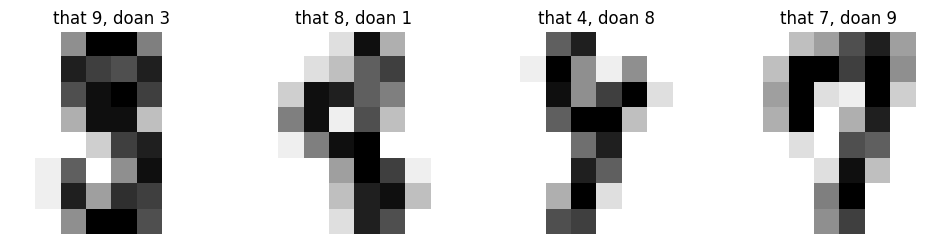

In [14]:
X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
svm = SVC(kernel="rbf").fit(X_tr, y_tr)
du_doan = svm.predict(X_te)

print("Hang la chu so that, cot la chu so doan")
print(confusion_matrix(y_te, du_doan))

sai = np.flatnonzero(du_doan != y_te)
fig, axes = plt.subplots(1, len(sai), figsize=(3 * len(sai), 3))
for ax, i in zip(np.atleast_1d(axes), sai):
    ax.imshow(X_te[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"that {y_te[i]}, doan {du_doan[i]}")
    ax.axis("off")
plt.savefig("anh_doan_sai.png", dpi=120, bbox_inches="tight")
plt.show()

In [15]:
import time

print("      n    SVC (s)   LinearSVC (s)")
ket_qua = []
for n in [2000, 5000, 10000, 20000]:
    X, y = make_classification(n_samples=n, n_features=20, random_state=0)

    t0 = time.time(); SVC().fit(X, y); t_svc = time.time() - t0
    t0 = time.time(); LinearSVC(max_iter=10000).fit(X, y); t_lin = time.time() - t0

    ket_qua.append((n, t_svc, t_lin))
    print(f"{n:7d}  {t_svc:8.3f}  {t_lin:12.3f}")

print()
for (n1, a1, b1), (n2, a2, b2) in zip(ket_qua, ket_qua[1:]):
    print(f"{n1} -> {n2}: SVC tang {a2 / a1:.1f} lan, LinearSVC tang {b2 / b1:.1f} lan")

      n    SVC (s)   LinearSVC (s)
   2000     0.101         0.006
   5000     0.667         0.012
  10000     4.775         0.014
  20000    11.557         0.031

2000 -> 5000: SVC tang 6.6 lan, LinearSVC tang 2.0 lan
5000 -> 10000: SVC tang 7.2 lan, LinearSVC tang 1.2 lan
10000 -> 20000: SVC tang 2.4 lan, LinearSVC tang 2.2 lan
